### MSCS 634 — Project Deliverable 2: Regression Modeling and Performance Evaluation
**Name:** Aditya Rayarapu
**Project:** IPL Cricket Analytics 
**Research question:** Can first-innings IPL totals be predicted using information available at the start of the innings?  
**Dataset:** Same match and ball-by-ball files as Deliverable 1, accessed through direct raw GitHub URLs.  
**Reproducibility:** Run every cell in order. The final cells automatically save charts, results, and a README containing **measured** results.

**Important distinction:** Predictions are made **before any ball is bowled**, not after knowing the match winner, actual target, runs scored, wickets, or innings duration. All scoring features derived from ball-by-ball data are used to create the **target** only. The train/test split is chronological to test generalization to a later IPL season.

### 1. Imports, configuration, and direct URL loading

The loaded files are match-level (`matches.csv`) and delivery-level (`deliveries.csv`) data from a public repository. The original Deliverable 1 submission used the same URLs. The fallback uses verified SSL certificates instead of disabling SSL verification. **No local IPL CSV files are required.**

In [3]:
pip install --upgrade certifi requests



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
from io import BytesIO
from datetime import datetime, timezone
import ssl
import certifi
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110, "savefig.dpi": 160})
IMG_DIR = Path("screenshots")
RESULT_DIR = Path("results")
IMG_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE = "https://raw.githubusercontent.com/elavarasan-ai/IPL-Data-Analysis/main/"
MATCHES_URL = SOURCE + "matches.csv"
DELIVERIES_URL = SOURCE + "deliveries.csv"

def load_url_csv(url):
    """Load remote data securely; retry with Requests+certifi on macOS SSL errors."""
    try:
        return pd.read_csv(url)
    except (OSError, ssl.SSLError) as initial_error:
        print("Retrying with the certifi CA bundle:", str(initial_error)[:120])
        response = requests.get(url, timeout=180, verify=certifi.where())
        response.raise_for_status()
        return pd.read_csv(BytesIO(response.content))

matches_raw = load_url_csv(MATCHES_URL)
deliveries_raw = load_url_csv(DELIVERIES_URL)
accessed_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
print(f"Loaded {len(matches_raw):,} match rows ({matches_raw.shape[1]} columns)")
print(f"Loaded {len(deliveries_raw):,} delivery rows ({deliveries_raw.shape[1]} columns)")
print("Accessed:", accessed_utc)
print("Matches columns:", matches_raw.columns.to_list())
print("Delivery columns:", deliveries_raw.columns.to_list())
assert len(matches_raw) >= 500 and matches_raw.shape[1] >= 8
assert len(deliveries_raw) >= 500 and deliveries_raw.shape[1] >= 8

Retrying with the certifi CA bundle: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.
Retrying with the certifi CA bundle: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.
Loaded 1,095 match rows (20 columns)
Loaded 260,920 delivery rows (17 columns)
Accessed: 2026-11-11 21:20 UTC
Matches columns: ['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']
Delivery columns: ['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


### 2. Reuse Deliverable 1 cleaning and record data-quality decisions

The original frames are preserved. Historical *name changes* are harmonized (Delhi, Punjab, Bengaluru); defunct or distinct franchises are **not** automatically merged. Blank text fields are normalized; IDs, dates, and runs are coerced to numeric/date types. The original source's `season` strings include values such as `2007/08`, so **calendar year is derived from the actual match date** rather than interpreting a season string as a number.

We explicitly quantify invalid IDs, duplicate match records, missing dates, unknown match references, duplicate deliveries, and negative scores. Missing winner information does not make a match invalid for regression; no-result / rain-adjusted matches are excluded by a documented modeling rule below.

In [5]:
TEAM_ALIASES = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}

def strip_text_fields(df):
    out = df.copy()
    for name in out.select_dtypes(include=["object", "string"]).columns:
        out[name] = out[name].astype("string").str.strip().replace("", pd.NA)
    return out

matches = strip_text_fields(matches_raw)
deliveries = strip_text_fields(deliveries_raw)
matches = matches.rename(columns={"id": "match_id"})
deliveries = deliveries.rename(columns={"inning": "innings"})

required_match = {"match_id", "date", "team1", "team2", "toss_winner", "toss_decision", "venue", "city", "match_type", "method", "target_overs", "result"}
required_delivery = {"match_id", "innings", "total_runs", "batting_team", "bowling_team"}
assert required_match.issubset(matches.columns), f"Missing match columns: {required_match - set(matches.columns)}"
assert required_delivery.issubset(deliveries.columns), f"Missing delivery columns: {required_delivery - set(deliveries.columns)}"

for df in (matches, deliveries):
    for name in ("team1", "team2", "toss_winner", "batting_team", "bowling_team"):
        if name in df:
            df[name] = df[name].replace(TEAM_ALIASES)

matches["match_id"] = pd.to_numeric(matches["match_id"], errors="coerce")
deliveries["match_id"] = pd.to_numeric(deliveries["match_id"], errors="coerce")
for name in ("innings", "total_runs"):
    deliveries[name] = pd.to_numeric(deliveries[name], errors="coerce")
matches["date"] = pd.to_datetime(matches["date"], errors="coerce")
matches["target_overs"] = pd.to_numeric(matches["target_overs"], errors="coerce")

quality = {
    "match_rows_raw": len(matches_raw),
    "delivery_rows_raw": len(deliveries_raw),
    "duplicate_match_id_rows": int(matches["match_id"].duplicated().sum()),
    "duplicate_delivery_rows": int(deliveries.duplicated().sum()),
    "invalid_match_ids": int(matches["match_id"].isna().sum()),
    "invalid_delivery_ids": int(deliveries["match_id"].isna().sum()),
    "invalid_dates": int(matches["date"].isna().sum()),
    "negative_delivery_runs": int((deliveries["total_runs"] < 0).sum()),
    "unknown_delivery_match_ids": int((~deliveries["match_id"].isin(matches["match_id"])).sum()),
    "missing_match_winners": int(matches["winner"].isna().sum()) if "winner" in matches else None,
}
display(pd.DataFrame.from_dict(quality, orient="index", columns=["Count"]))

# Never silently overwrite duplicate IDs: the first-innings join assumes one row per match.
if quality["duplicate_match_id_rows"]:
    raise ValueError("Duplicate match IDs require investigation before regression.")
# Exact duplicate delivery records are checked rather than arbitrarily dropped;
# even a repeated-looking ball record may be meaningful without sequence context.
if quality["duplicate_delivery_rows"]:
    raise ValueError("Duplicate delivery rows found: inspect original source before proceeding.")

,Count
match_rows_raw,1095
delivery_rows_raw,260920
duplicate_match_id_rows,0
duplicate_delivery_rows,0
invalid_match_ids,0
invalid_delivery_ids,0
invalid_dates,0
negative_delivery_runs,0
unknown_delivery_match_ids,0
missing_match_winners,5


### 3. Define the target and model-eligible matches

**Target:** `first_innings_runs` = sum of `total_runs` for `innings == 1`, one observation per match. The first innings is chosen to avoid target-chasing strategies that affect second-innings scores.

For a more interpretable **standard-overs** modeling population, exclude matches with a declared shortened target (`target_overs < 20`), nonmissing weather-adjustment method, no result, or invalid dates / scores. These are **selection rules**, not predictor variables. Completed all-out innings are retained even if their total is unusually low. We do not discard high-scoring outliers without evidence of corruption.

**Important limitation:** Excluding rain-affected matches after the event means the model applies to ordinary, completed games and is **not** an all-weather forecast. `target_overs` is not used as a feature. No information from the actual first innings (runs, wickets, overs, deliveries) is included among predictors.

In [6]:
# Calculate first-innings totals from the ball-level source. Keep first bowling
# / batting identities ONLY for a consistency check, not as model predictors.
valid_balls = deliveries.loc[
    deliveries["innings"].eq(1)
    & deliveries["total_runs"].notna()
    & deliveries["total_runs"].ge(0)
    & deliveries["match_id"].notna()
].copy()
first_innings = (
    valid_balls.groupby("match_id", as_index=False)
    .agg(first_innings_runs=("total_runs", "sum"),
         deliveries_recorded=("total_runs", "size"),
         observed_batting_team=("batting_team", "first"),
         observed_bowling_team=("bowling_team", "first"))
)
match_data = matches.merge(first_innings, on="match_id", how="inner", validate="one_to_one")
initial_joined = len(match_data)

# Derive who bats first using ONLY the toss record and the two participating teams.
# These facts are available before the innings, unlike the match winner or score.
toss_winner_valid = match_data["toss_winner"].eq(match_data["team1"]) | match_data["toss_winner"].eq(match_data["team2"])
toss_decision_valid = match_data["toss_decision"].isin(["bat", "field"])
match_data = match_data.loc[toss_winner_valid & toss_decision_valid].copy()
match_data["other_team"] = np.where(
    match_data["toss_winner"].eq(match_data["team1"]), match_data["team2"], match_data["team1"]
)
match_data["batting_first"] = np.where(match_data["toss_decision"].eq("bat"),
                                        match_data["toss_winner"], match_data["other_team"])
match_data["bowling_first"] = np.where(match_data["toss_decision"].eq("field"),
                                        match_data["toss_winner"], match_data["other_team"])

# Check toss-based pre-innings identities against actual innings records.
team_mismatch = (
    match_data["observed_batting_team"].notna()
    & match_data["batting_first"].ne(match_data["observed_batting_team"])
)
print("Toss/team vs first-innings team mismatches:", int(team_mismatch.sum()))
if team_mismatch.any():
    display(match_data.loc[team_mismatch, ["match_id", "date", "batting_first", "observed_batting_team"]].head())
# Exclude mismatches pending investigation, instead of using observed score-era features.
match_data = match_data.loc[~team_mismatch].copy()

# Filters for the declared intended population: ordinary, completed matches.
eligible = (
    match_data["date"].notna()
    & match_data["first_innings_runs"].notna()
    & match_data["first_innings_runs"].ge(0)
    & match_data["method"].isna()
    & ~match_data["result"].fillna("unknown").str.lower().eq("no result")
    & (match_data["target_overs"].isna() | match_data["target_overs"].ge(20))
)
model_df = match_data.loc[eligible].copy()
model_df["season_year"] = model_df["date"].dt.year.astype(int)
model_df["month"] = model_df["date"].dt.month.astype(int)

# Normalize categorical labels and use explicit 'Unknown' rather than dropping rows.
for name in ["batting_first", "bowling_first", "toss_decision", "city", "venue", "match_type"]:
    model_df[name] = model_df[name].astype("string").fillna("Unknown").str.strip().replace("", "Unknown").astype(str)
model_df["venue"] = model_df["venue"].str.replace(r"\s+", " ", regex=True)
model_df = model_df.sort_values(["date", "match_id"]).reset_index(drop=True)

assert len(model_df) >= 150, "Too few modeled matches; inspect exclusions and source data."
assert model_df["season_year"].nunique() >= 3, "Need multiple seasons for chronological evaluation."
print(f"Matches with first innings: {initial_joined:,}")
print(f"Eligible regular-match observations: {len(model_df):,}")
print(f"Excluded after first-innings join (all filters combined): {initial_joined - len(model_df):,}")
print("Calendar years:", model_df["season_year"].min(), "to", model_df["season_year"].max())
print("First innings total descriptive statistics:")
display(model_df["first_innings_runs"].describe().to_frame("runs"))
display(model_df[["date", "batting_first", "bowling_first", "venue", "toss_decision", "first_innings_runs"]].head(8))

Toss/team vs first-innings team mismatches: 0
Matches with first innings: 1,095
Eligible regular-match observations: 1,061
Excluded after first-innings join (all filters combined): 34
Calendar years: 2008 to 2024
First innings total descriptive statistics:


,runs
count,1061.000000
mean,166.390198
std,31.400163
min,67.000000
25%,147.000000
50%,166.000000
75%,187.000000
max,287.000000


,date,batting_first,bowling_first,venue,toss_decision,first_innings_runs
0,2008-04-18,Kolkata Knight Riders,Royal Challengers Bengaluru,M Chinnaswamy Stadium,field,222
1,2008-04-19,Chennai Super Kings,Punjab Kings,"Punjab Cricket Association Stadium, Mohali",bat,240
2,2008-04-19,Rajasthan Royals,Delhi Capitals,Feroz Shah Kotla,bat,129
3,2008-04-20,Mumbai Indians,Royal Challengers Bengaluru,Wankhede Stadium,bat,165
4,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Eden Gardens,bat,110
5,2008-04-21,Punjab Kings,Rajasthan Royals,Sawai Mansingh Stadium,bat,166
6,2008-04-22,Deccan Chargers,Delhi Capitals,"Rajiv Gandhi International Stadium, Uppal",bat,142
7,2008-04-23,Chennai Super Kings,Mumbai Indians,"MA Chidambaram Stadium, Chepauk",field,208


### 4. Feature engineering and leakage audit

| Predictor | Type | Why it is available and relevant |
|---|---|---|
| Season year | Numeric | Can capture broad IPL scoring trends |
| Match month | Numeric | Represents seasonal timing (context, not causality) |
| Batting-first team | Categorical | Batting strength and roster identity |
| Bowling-first team | Categorical | Opposition bowling strength and tactics |
| Venue and city | Categorical | Ground and local conditions; may be incomplete |
| Toss decision | Categorical | Known before the innings; possible tactical context |
| Match type | Categorical | League/playoff context known before play |

Categorical variables are one-hot encoded with `handle_unknown='ignore'`. Numeric features are imputed and scaled **inside pipelines** fit on each training fold, so validation and test information cannot influence preprocessing. Unknown future teams / venues map to all-zero dummy categories in the holdout. Historical identity changes are harmonized only when they represent name changes.

**Excluded intentionally:** `winner`, `result_margin`, `target_runs`, `target_overs`, `first_innings_runs` (predictor side), runs/wickets/balls, `player_of_match`, `method`, dismissal totals. These include post-match/post-innings data or unsupported future availability.

In [7]:
NUMERIC_FEATURES = ["season_year", "month"]
CATEGORICAL_FEATURES = ["batting_first", "bowling_first", "venue", "city", "toss_decision", "match_type"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "first_innings_runs"

# A chronological split provides a final untouched later-season benchmark.
# We use ALL data before the newest calendar season for model development.
latest_year = int(model_df["season_year"].max())
train_df = model_df.loc[model_df["season_year"] < latest_year].copy()
test_df = model_df.loc[model_df["season_year"] == latest_year].copy()
assert len(train_df) >= 100 and len(test_df) >= 15, "Insufficient training/test observations; inspect season coverage."

X_train, y_train = train_df[FEATURES], train_df[TARGET].astype(float)
X_test, y_test = test_df[FEATURES], test_df[TARGET].astype(float)
print(f"Training: {len(X_train):,} games through {latest_year - 1}")
print(f"Held-out test: {len(X_test):,} games in {latest_year}")
print("Features:", FEATURES)
print("Target:", TARGET)

# Demonstrate standard baseline and reproducible pipeline preprocessing.
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

Training: 991 games through 2023
Held-out test: 70 games in 2024
Features: ['season_year', 'month', 'batting_first', 'bowling_first', 'venue', 'city', 'toss_decision', 'match_type']
Target: first_innings_runs


### 5. Train baseline and at least two regression models

- **DummyRegressor:** predicts the mean of training scores; non-ML benchmark.
- **Linear Regression:** least-squares additive effects, no regularization.
- **Ridge Regression:** linear model with L2 penalty to reduce unstable coefficients when categories are correlated or sparse.
- **Random Forest Regression:** nonlinear trees can learn venue/team interactions without requiring them to be manually specified.

Ridge strength (`alpha=50`) and Random Forest settings are fixed before examining the holdout. These are illustrative values; hyperparameter tuning can be conducted within a nested CV design in future work.

In [8]:
estimators = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=50.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3, max_features=0.8,
        random_state=SEED, n_jobs=-1
    ),
}
models = {
    name: Pipeline([("prep", preprocess), ("model", estimator)])
    for name, estimator in estimators.items()
}
print("Regression models:", ", ".join(models))

Regression models: Mean baseline, Linear Regression, Ridge Regression, Random Forest


### 6. Expanding-window cross-validation (training seasons only)

Cross-validation is **chronological**, not random: each fold trains on earlier matches and validates on later matches. `TimeSeriesSplit(n_splits=5)` avoids training on future results relative to its validation fold. There is no match overlap between folds' training and validation periods, though matches from the same calendar year may occur on both sides in chronological order.

**Selection rule:** Choose the model with the **lowest average CV RMSE** on the training period. Keep the held-out newest season completely untouched until after selection. Negative R² is possible and indicates worse-than-mean fit, not a coding error.

In [9]:
cv = TimeSeriesSplit(n_splits=5)
scoring = {"r2": "r2", "neg_mse": "neg_mean_squared_error", "neg_mae": "neg_mean_absolute_error"}
cv_records = []
for name, pipeline in models.items():
    fold_metrics = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=1, error_score="raise"
    )
    fold_rmse = np.sqrt(-fold_metrics["test_neg_mse"])
    cv_records.append({
        "Model": name,
        "CV_RMSE_mean": float(fold_rmse.mean()),
        "CV_RMSE_std": float(fold_rmse.std(ddof=1)),
        "CV_MAE_mean": float((-fold_metrics["test_neg_mae"]).mean()),
        "CV_R2_mean": float(fold_metrics["test_r2"].mean()),
    })
cv_results = pd.DataFrame(cv_records).sort_values("CV_RMSE_mean").reset_index(drop=True)
selected_model_name = cv_results.iloc[0]["Model"]
cv_results.to_csv(RESULT_DIR / "cross_validation_metrics.csv", index=False)
display(cv_results.round(3))
print("CV-selected model (lowest average RMSE):", selected_model_name)

,Model,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_R2_mean
0,Ridge Regression,30.228,0.855,23.767,-0.039
1,Mean baseline,30.551,1.548,23.955,-0.059
2,Random Forest,31.104,1.006,24.474,-0.099
3,Linear Regression,32.465,1.399,25.532,-0.203


CV-selected model (lowest average RMSE): Ridge Regression


### 7. Final untouched test season and model comparison

Fit all candidate models using the earlier-season training set and assess them on the same unseen season. Report **R²**, **MSE**, **RMSE** (runs), and **MAE** (runs). The table explicitly distinguishes which method CV selected from which method happened to score best on the holdout. Model choice is **not** retroactively optimized on the test season.

In [10]:
test_records = []
predictions = pd.DataFrame({
    "match_id": test_df["match_id"].to_numpy(),
    "date": test_df["date"].dt.strftime("%Y-%m-%d").to_numpy(),
    "actual_runs": y_test.to_numpy(),
})
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    test_records.append({
        "Model": name,
        "Test_R2": float(r2_score(y_test, y_pred)),
        "Test_MSE": float(mse),
        "Test_RMSE": float(np.sqrt(mse)),
        "Test_MAE": float(mean_absolute_error(y_test, y_pred)),
    })
    predictions[name] = y_pred

holdout_results = pd.DataFrame(test_records).sort_values("Test_RMSE").reset_index(drop=True)
comparison = cv_results.merge(holdout_results, on="Model", validate="one_to_one")
comparison = comparison.sort_values("CV_RMSE_mean").reset_index(drop=True)
comparison.to_csv(RESULT_DIR / "model_comparison.csv", index=False)
predictions.to_csv(RESULT_DIR / "holdout_predictions.csv", index=False)
display(comparison.round(3))
print("CV-selected:", selected_model_name)
print("Lowest holdout RMSE (descriptive only):", holdout_results.iloc[0]["Model"])

,Model,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_R2_mean,Test_R2,Test_MSE,Test_RMSE,Test_MAE
0,Ridge Regression,30.228,0.855,23.767,-0.039,-0.087,1597.615,39.970,30.227
1,Mean baseline,30.551,1.548,23.955,-0.059,-0.437,2112.188,45.959,35.239
2,Random Forest,31.104,1.006,24.474,-0.099,-0.047,1538.568,39.225,30.355
3,Linear Regression,32.465,1.399,25.532,-0.203,-0.126,1655.950,40.693,31.692


CV-selected: Ridge Regression
Lowest holdout RMSE (descriptive only): Random Forest


### 8. Comparative visualizations

Plots are generated from **real validation and test predictions**, never hard-coded scores. Every chart is saved as an image in `screenshots/` for your GitHub submission.

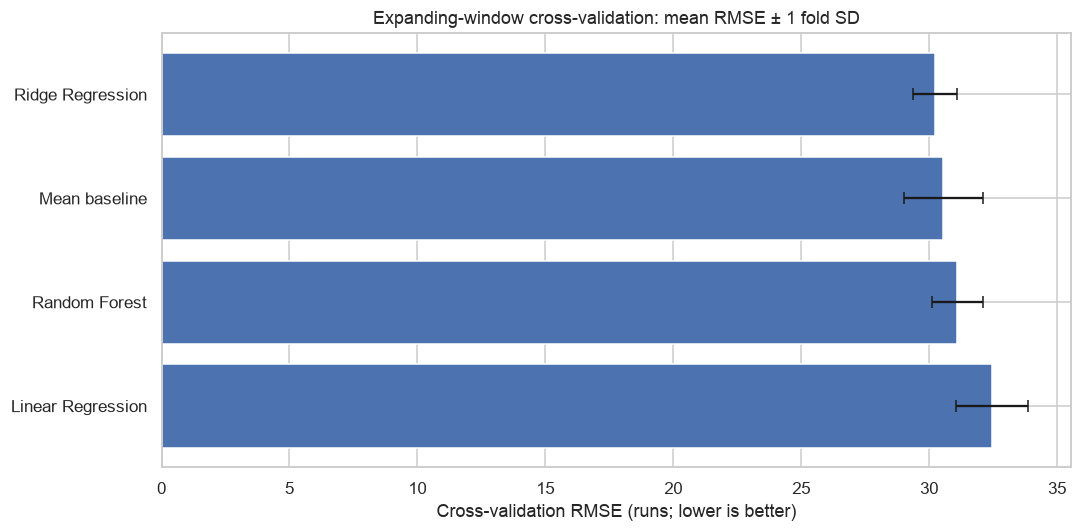

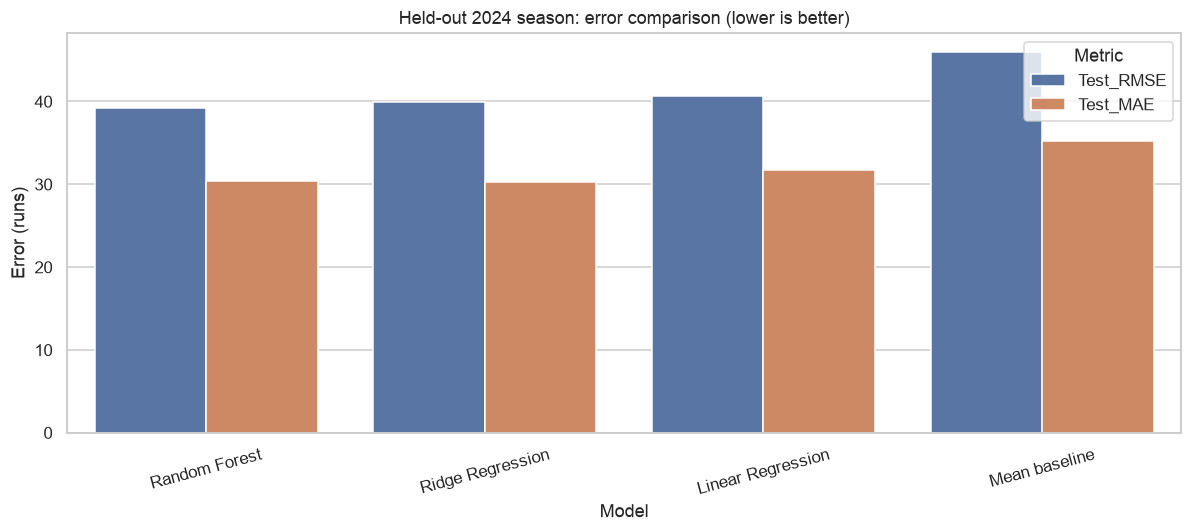

In [11]:
# Figure 1: 5-fold CV RMSE with standard deviation (lower is better).
fig, ax = plt.subplots(figsize=(10, 5))
p = cv_results.sort_values("CV_RMSE_mean")
ax.barh(p["Model"], p["CV_RMSE_mean"], xerr=p["CV_RMSE_std"], capsize=4)
ax.invert_yaxis()
ax.set(xlabel="Cross-validation RMSE (runs; lower is better)",
       title="Expanding-window cross-validation: mean RMSE ± 1 fold SD")
plt.tight_layout()
fig.savefig(IMG_DIR / "01_cv_rmse.png", bbox_inches="tight")
plt.show()

# Figure 2: Holdout RMSE and MAE for every model.
long_errors = holdout_results.melt(id_vars="Model", value_vars=["Test_RMSE", "Test_MAE"],
                                    var_name="Metric", value_name="Error (runs)")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=long_errors, x="Model", y="Error (runs)", hue="Metric", ax=ax)
ax.set_title(f"Held-out {latest_year} season: error comparison (lower is better)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
fig.savefig(IMG_DIR / "02_holdout_errors.png", bbox_inches="tight")
plt.show()

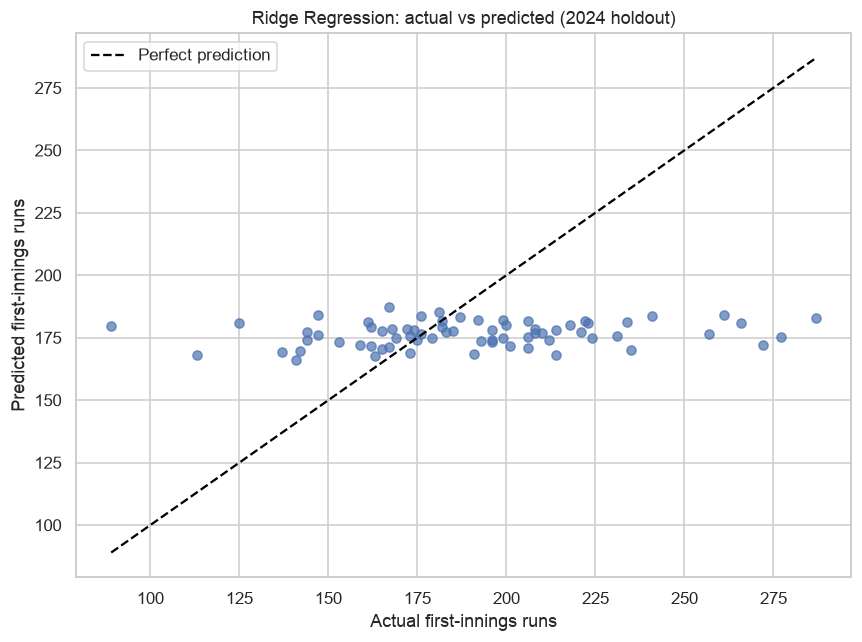

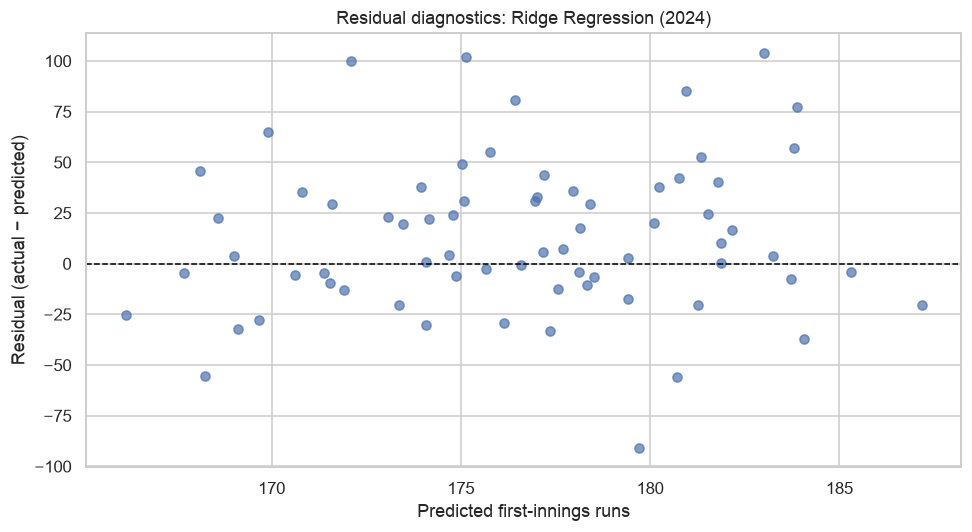

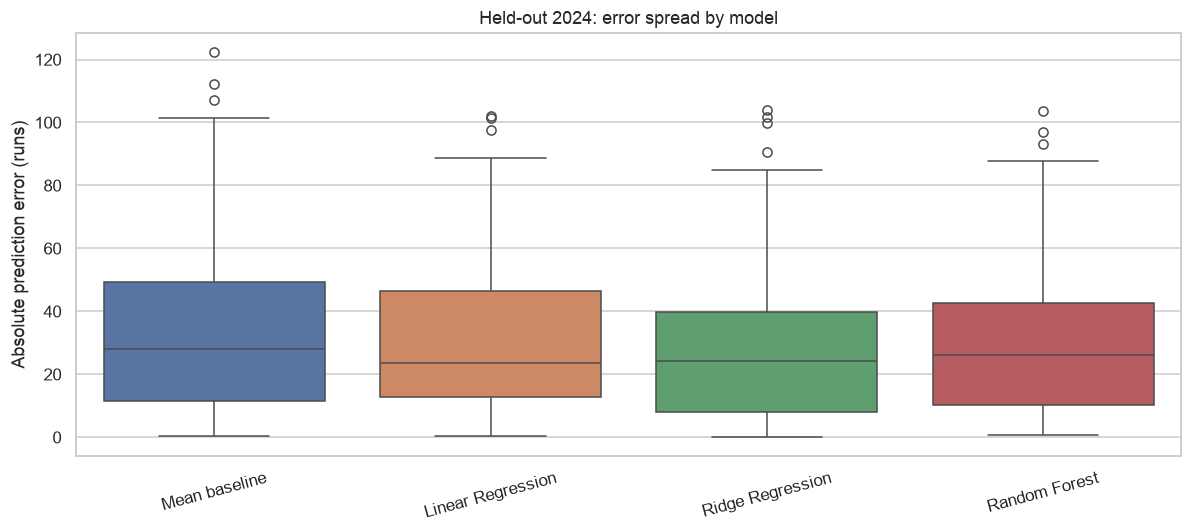

In [12]:
# Figure 3: Measured versus predicted scores for the model selected by CV.
actual = predictions["actual_runs"].to_numpy()
pred = predictions[selected_model_name].to_numpy()
low = float(min(actual.min(), pred.min()))
high = float(max(actual.max(), pred.max()))
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(actual, pred, alpha=0.7)
ax.plot([low, high], [low, high], linestyle="--", color="black", label="Perfect prediction")
ax.set(xlabel="Actual first-innings runs", ylabel="Predicted first-innings runs",
       title=f"{selected_model_name}: actual vs predicted ({latest_year} holdout)")
ax.legend()
plt.tight_layout()
fig.savefig(IMG_DIR / "03_actual_vs_predicted.png", bbox_inches="tight")
plt.show()

# Figure 4: Prediction residuals; zero line marks unbiased errors.
residual = actual - pred
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pred, residual, alpha=0.7)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Predicted first-innings runs", ylabel="Residual (actual − predicted)",
       title=f"Residual diagnostics: {selected_model_name} ({latest_year})")
plt.tight_layout()
fig.savefig(IMG_DIR / "04_residuals.png", bbox_inches="tight")
plt.show()

# Figure 5: Distribution of absolute prediction errors across candidates.
error_frame = pd.DataFrame({name: np.abs(actual - predictions[name].to_numpy())
                            for name in models})
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=error_frame, ax=ax)
ax.set(ylabel="Absolute prediction error (runs)",
       title=f"Held-out {latest_year}: error spread by model")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
fig.savefig(IMG_DIR / "05_absolute_error_spread.png", bbox_inches="tight")
plt.show()

### 9. Interpretation of real measurements

The following narrative is **computed** from your actual outputs when you execute the notebook. It covers model ranking, baseline improvements, test-season generalization, the main error scale, and limitations. Read it carefully and adjust the discussion if the numbers reveal an unexpected pattern.

In [18]:
selected_row = comparison.loc[comparison["Model"].eq(selected_model_name)].iloc[0]
baseline_row = comparison.loc[comparison["Model"].eq("Mean baseline")].iloc[0]
holdout_winner = holdout_results.iloc[0]
relative_rmse = 100 * (baseline_row["Test_RMSE"] - selected_row["Test_RMSE"]) / baseline_row["Test_RMSE"]
residual_bias = float((y_test.to_numpy() - predictions[selected_model_name].to_numpy()).mean())
train_mean = float(y_train.mean())
test_mean = float(y_test.mean())

measured_interpretation = f"""
### Results and discussion — measured from the dataset

- **Dataset/model population:** {len(matches_raw):,} original match records and {len(deliveries_raw):,} delivery records; **{len(model_df):,}** matches meet the first-innings and regular-match inclusion criteria. The year range is {model_df.season_year.min()}–{latest_year}. Model development contains {len(train_df):,} earlier matches and the untouched **{latest_year}** season contains {len(test_df):,} matches.
- **Feature engineering:** Models use **{len(FEATURES)} pre-innings fields** ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical). One-hot encoding, missing-value handling, and scaling occur inside every CV fold's training pipeline.
- **Cross-validation:** **{selected_model_name}** had the lowest mean expanding-window CV RMSE at **{selected_row.CV_RMSE_mean:.2f} ± {selected_row.CV_RMSE_std:.2f} runs** across five validation folds. Its average CV R² was **{selected_row.CV_R2_mean:.3f}**.
- **Unseen-season evaluation:** The CV-selected model's held-out **R² = {selected_row.Test_R2:.3f}**, **MSE = {selected_row.Test_MSE:.2f}**, **RMSE = {selected_row.Test_RMSE:.2f} runs**, and **MAE = {selected_row.Test_MAE:.2f} runs**. The baseline RMSE was **{baseline_row.Test_RMSE:.2f} runs**, a **{relative_rmse:+.1f}% reduction** in RMSE for the selected model (negative means worse than baseline).
- **Model comparison:** **{holdout_winner.Model}** had the lowest test RMSE of **{holdout_winner.Test_RMSE:.2f} runs**, but the choice of model was determined using earlier-season CV rather than revising the decision after looking at the test season.
- **Scoring shift:** Average first-innings totals changed from **{train_mean:.2f} runs** in training years to **{test_mean:.2f} runs** in the held-out year. The selected model's mean residual was **{residual_bias:+.2f} runs** (actual minus predicted), which shows the direction of average forecast bias.
- **Interpretation and limitations:** Lower RMSE means more accurate run forecasts; R² shows how much unseen-season variance the model explains relative to the test mean. First-innings runs depend on unrecorded pitch quality, weather, player availability, tactical changes, and squad composition, so pre-innings attributes alone may have limited forecasting power. Time-based testing is harder and more realistic than randomly splitting future and past IPL matches. Do **not** claim causation from team/venue coefficients.
"""
display(Markdown(measured_interpretation))


### Results and discussion — measured from the dataset

- **Dataset/model population:** 1,095 original match records and 260,920 delivery records; **1,061** matches meet the first-innings and regular-match inclusion criteria. The year range is 2008–2024. Model development contains 991 earlier matches and the untouched **2024** season contains 70 matches.
- **Feature engineering:** Models use **8 pre-innings fields** (2 numeric, 6 categorical). One-hot encoding, missing-value handling, and scaling occur inside every CV fold's training pipeline.
- **Cross-validation:** **Ridge Regression** had the lowest mean expanding-window CV RMSE at **30.23 ± 0.85 runs** across five validation folds. Its average CV R² was **-0.039**.
- **Unseen-season evaluation:** The CV-selected model's held-out **R² = -0.087**, **MSE = 1597.61**, **RMSE = 39.97 runs**, and **MAE = 30.23 runs**. The baseline RMSE was **45.96 runs**, a **+13.0% reduction** in RMSE for the selected model (negative means worse than baseline).
- **Model comparison:** **Random Forest** had the lowest test RMSE of **39.22 runs**, but the choice of model was determined using earlier-season CV rather than revising the decision after looking at the test season.
- **Scoring shift:** Average first-innings totals changed from **164.72 runs** in training years to **190.06 runs** in the held-out year. The selected model's mean residual was **+13.48 runs** (actual minus predicted), which shows the direction of average forecast bias.
- **Interpretation and limitations:** Lower RMSE means more accurate run forecasts; R² shows how much unseen-season variance the model explains relative to the test mean. First-innings runs depend on unrecorded pitch quality, weather, player availability, tactical changes, and squad composition, so pre-innings attributes alone may have limited forecasting power. Time-based testing is harder and more realistic than randomly splitting future and past IPL matches. Do **not** claim causation from team/venue coefficients.


### 10. Reproducible report and final submission files

This final cell writes a complete README **with real metrics**, not placeholder text, plus a small execution summary. Re-run it after any model changes. The saved images and CSV result tables are designed for direct GitHub inspection. The original source CSVs remain remote and are not redistributed.

In [14]:
%pip install tabulate

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  NOTE: The current PATH contains path(s) starting with `~`, which may not be expanded by all applications.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import json

readme_text = f"""# MSCS 634 — IPL Cricket Analytics, Deliverable 2

## Objective and dataset
Predict first-innings IPL runs from information available at the start of the innings. This builds on [Deliverable 1](https://github.com/arayarapu/MSCS_634_Project_Deliverable_1) with the same public IPL source dataset. The data were accessed on **{accessed_utc}**.

- [Match CSV]({MATCHES_URL}) — **{len(matches_raw):,} rows, {matches_raw.shape[1]} attributes**.
- [Delivery CSV]({DELIVERIES_URL}) — **{len(deliveries_raw):,} rows, {deliveries_raw.shape[1]} attributes**.
- Modeling subset: **{len(model_df):,}** ordinary, completed matches across **{model_df.season_year.min()}–{latest_year}**; **{len(train_df):,}** train and **{len(test_df):,}** held-out **{latest_year}** records.
- Data provenance: [elavarasan-ai/IPL-Data-Analysis](https://github.com/elavarasan-ai/IPL-Data-Analysis); original match and ball-by-ball source as described by that repository. No source CSVs are committed.

## Cleaning and feature engineering
1. Load both remote CSVs; preserve original copies and validate schema and row counts.
2. Normalize whitespace and historic franchise name changes; distinguish renamed franchises from distinct teams. Validate match IDs, dates, scores, and duplicate rows.
3. Aggregate `inning == 1` delivery runs to one target per match. Exclude matches affected by declared shortened targets, weather-adjustment methods, no result, missing date/score or contradictory team records. Fully bowled-out innings are retained.
4. Build pre-innings features: `season_year`, `month`, `batting_first`, `bowling_first`, `venue`, `city`, `toss_decision`, and `match_type`.
5. Impute, scale numeric features, and one-hot encode categories **within pipelines fit only to the training data**. Final match winner, scores, wickets, target runs, and target overs are **never used as predictors**.

### Cleaning observations
- Raw duplicate match IDs: **{quality['duplicate_match_id_rows']}**; raw exact duplicate delivery rows: **{quality['duplicate_delivery_rows']}**.
- Invalid match IDs: **{quality['invalid_match_ids']}**; invalid delivery IDs: **{quality['invalid_delivery_ids']}**; invalid dates: **{quality['invalid_dates']}**.
- Unknown delivery match references: **{quality['unknown_delivery_match_ids']}**; negative delivery runs: **{quality['negative_delivery_runs']}**; match records without first innings or excluded by regular-match criteria: **{initial_joined - len(model_df)}** after first-innings join.

## Models and evaluation
All models use an **expanding-window 5-fold TimeSeriesSplit** on earlier matches. The newest calendar season (**{latest_year}**) is a final untouched test set. Models: mean baseline, Linear Regression, Ridge Regression (L2, alpha=50), and Random Forest Regression (200 trees; min leaf=3). The model selected for discussion is the one with the lowest CV RMSE; no hyperparameters are tuned on the test season.

### Regression performance (runs unless otherwise indicated)
{comparison.round(3).to_markdown(index=False)}

{measured_interpretation}

## Charts and result files
- `screenshots/01_cv_rmse.png`: mean ± SD across chronological CV folds.
- `screenshots/02_holdout_errors.png`: test RMSE and MAE by model.
- `screenshots/03_actual_vs_predicted.png`: actual vs predicted runs for CV-selected model.
- `screenshots/04_residuals.png`: residual bias and error pattern.
- `screenshots/05_absolute_error_spread.png`: test absolute error distributions.
- `results/cross_validation_metrics.csv`, `results/model_comparison.csv`, `results/holdout_predictions.csv`: measured results for reproducibility.

## Challenges, decisions, and limitations
- **Season labels** in source may be strings such as `2007/08`; derive calendar year from the match date, ensuring consistent chronological splitting.
- **Franchise names** evolve; standardize clear name changes, but do not merge historically distinct franchises.
- **Rain and abandoned matches:** exclude declared shortened/adjusted games for the intended standard-match target; retain plausible extremely high/low totals rather than deleting them by a generic outlier cutoff.
- **Leakage:** one row per match; only pre-innings predictors; a chronological holdout and in-fold transformers prevent information from unseen seasons affecting training.
- **Unobserved factors:** player availability, weather, ground conditions and match strategy may prevent accurate point predictions. Cross-validation and holdout performance are reported without claiming causal interpretation.

## Reproduce on Mac (internet connection needed)
```bash
python3 -m pip install -r requirements.txt
python3 -m jupyter lab
```
Open `IPL_Deliverable_2_Regression.ipynb`, select **Run → Run All Cells**, and verify the notebook writes this README plus the chart/metrics outputs. If macOS cannot validate certificates, install system Python certificates or `certifi`; the notebook includes a verified-SSL retry and never disables validation.

## Submission: 
executed notebook 
README
requirements.txt
screenshots/ and
results/ 
"""
Path("README.md").write_text(readme_text, encoding="utf-8")
summary = {
    "source_match_rows": len(matches_raw), "source_delivery_rows": len(deliveries_raw),
    "eligible_matches": len(model_df), "train_matches": len(train_df),
    "test_matches": len(test_df), "test_year": latest_year,
    "cv_selected_model": selected_model_name,
    "holdout_best_rmse_model": str(holdout_winner.Model),
    "measured_at_utc": accessed_utc,
}
(RESULT_DIR / "execution_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved README.md and execution_summary.json with measured data.")
print("Saved", len(list(IMG_DIR.glob("*.png"))), "PNG charts and", len(list(RESULT_DIR.glob("*.csv"))), "CSV reports.")

Saved README.md and execution_summary.json with measured data.
Saved 5 PNG charts and 3 CSV reports.
